<a href="https://colab.research.google.com/github/beatriz-carrillo/ladb_mobility_economy_project/blob/main/S5_ladb_mobility_economy_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt




<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Importación limpia y adecuada de todas las librerías necesarias para el análisis.
</div>

In [ ]:
# cargar archivos

traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')


In [ ]:
# mostrar las primeras 5 filas de traffic
traffic.head()

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# mostrar las primeras 5 filas de eco
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"



---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [ ]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


En la estructura del DF traffic, se observa que:
- El DF contiene 1,004,464 registros y 12 columnas.
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son de tipo `object` pero deberian convertirse a `datetime64`, porque contienen fechas y horas. Esto permitirá trabajar con las fechas y extraer el año para filtrar 2024.
- La columna `JamsCount` tiene tipo `float64`, pero representa un conteo de embotellamientos, por lo que debería ser de tipo entero (`int64`). Antes de convertirla, se debe verificar que todos sus valores sean números enteros y válidos.

Las columnas `Country` y `City` tienen tipo `object`, adecuado para datos de texto. Las demás columnas numéricas tienen tipo `float64`, apropiado para medidas que pueden contener decimales.

**Datos ausentes:** `info()` no muestra valores nulos en ninguna columna: todas contienen 1,004,464 valores no nulos. Sin embargo, aún se debe revisar si existen cadenas vacías o valores utilizados para representar información faltante.

In [ ]:
# Examinar la estructura de eco
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF eco, se observa que:
- El DF contiene 30 registros y 7 columnas.
- Las siguientes columnas requieren conversión de `object` a `float64`, porque representan indicadores numéricos que pueden contener decimales:

- Columna `City GDP/capita` presenta valores como `15.782,00`. Se deben eliminar los puntos de miles y cambiar la coma decimal por un punto antes de convertirla.
- Columna `Unemployment %` presenta valores como `6.2%`. Se debe eliminar el símbolo `%` y convertirla a número, conservando la escala porcentual: 6.2 representa 6.2%.
- Columna `PM2.5 (μg/m³)` presenta valores con coma decimal, como `15,2`. Se debe sustituir la coma por un punto.
- Columna `Population (M)` presenta valores con coma decimal, como `15,30`. Se debe sustituir la coma por un punto, manteniendo la unidad en millones de habitantes.

La columna `Year` tiene tipo `int64`, adecuado para representar el año. `City` y `Country` tienen tipo `object`, apropiado para texto.

**Datos ausentes:** no se observan valores nulos según `info()`, ya que las siete columnas tienen 30 valores no nulos. Queda pendiente verificar si hay cadenas vacías u otros textos que representen datos faltantes.

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={"Country": "country", "City": "city","UpdateTimeUTC": "update_time_utc",
    "JamsDelay": "jams_delay",
    "TrafficIndexLive": "traffic_index_live",
    "JamsLengthInKms": "jams_length_in_kms", "JamsCount": "jams_count",
    "TrafficIndexWeekAgo": "traffic_index_week_ago",
    "UpdateTimeUTCWeekAgo": "update_time_utc_week_ago",
    "TravelTimeLivePer10KmsMins": "travel_time_live_per_10_kms_mins",
    "TravelTimeHistoricPer10KmsMins": "travel_time_historic_per_10_kms_mins",
    "MinsDelay": "mins_delay"
})


# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10_kms_mins',
       'travel_time_historic_per_10_kms_mins', 'mins_delay'],
      dtype='object')

In [ ]:
# Estandarizar los nombres de las columnas de eco

eco = eco.rename(columns={
    "Year": "year",
    "City": "city",
    "Country": "country",
    "City GDP/capita": "city_gdp_capita",
    "Unemployment %": "unemployment_pct",
    "PM2.5 (μg/m³)": "pm25_ug_m3",
    "Population (M)": "population_m"
})

# verificar cambios
eco.columns



Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25_ug_m3', 'population_m'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic["update_time_utc"] =  pd.to_datetime(traffic["update_time_utc"],errors="coerce",utc=True)
traffic["update_time_utc_week_ago"] = pd.to_datetime(traffic["update_time_utc_week_ago"],errors="coerce",utc=True)

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                                Non-Null Count    Dtype              
---  ------                                --------------    -----              
 0   country                               1004464 non-null  object             
 1   city                                  1004464 non-null  object             
 2   update_time_utc                       1004464 non-null  datetime64[ns, UTC]
 3   jams_delay                            1004464 non-null  float64            
 4   traffic_index_live                    1004464 non-null  float64            
 5   jams_length_in_kms                    1004464 non-null  float64            
 6   jams_count                            1004464 non-null  float64            
 7   traffic_index_week_ago                1004464 non-null  float64            
 8   update_time_utc_week_ago              1004464 non-null  datetime64[ns, U

In [ ]:

# Limpia separadores y convierte columnas numéricas en eco
eco["city_gdp_capita"] = (
    eco["city_gdp_capita"].astype(str).str.replace(".", "",regex=False).str.replace(",", ".",regex=False).astype(float)
)
eco["unemployment_pct"] = (
    eco["unemployment_pct"].astype(str).str.replace("%", "").str.replace(",", ".").astype(float)
)

eco["population_m"] = (
    eco["population_m"].astype(str).str.replace(",", ".").astype(float)
)


# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco["population"] = (eco["population_m"] * 1_000_000).round().astype("Int64")


# verificar el cambio
eco.info()
eco.head(3)




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25_ug_m3        30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     Int64  
dtypes: Int64(1), float64(3), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic["year"] = traffic["update_time_utc"].dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001000+00:00,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30+00:00,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00+00:00,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001000+00:00,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30+00:00,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30+00:00,8.196278,8.196510,-0.000232,2025


In [ ]:

# Filtra los registros del año 2024
traffic_2024 = traffic[traffic["year"] == 2024].copy()
eco_2024 = eco[eco["year"] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())

eco["year"].unique()

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30+00:00,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001000+00:00,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30+00:00,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30+00:00,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30+00:00,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30+00:00,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001000+00:00,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001000+00:00,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00+00:00,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00+00:00,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000


array([2023, 2024])

In [ ]:

# Los tiempos de viaje negativos no son válidos: reemplazarlos por NaN
columna = "mins_delay"
traffic_2024.loc[traffic_2024[columna] < 0, columna] = np.nan




---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [ ]:

# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = (
    traffic_2024
    .groupby(["city", "country", "year"])
    .agg({
        "jams_delay": "mean",
        "traffic_index_live": "mean",
        "jams_length_in_kms": "mean",
        "jams_count": "mean",
        "mins_delay": "mean",
        "travel_time_live_per_10_kms_mins": "mean",
        "travel_time_historic_per_10_kms_mins": "mean"
    })
    .reset_index()
)

# Mostrar resultado
traffic_city_year_2024.head()


,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,1.153410,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.907427,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.727301,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.463965,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.309805,15.879694,14.749945


In [ ]:
# Revisar estadísticas de las métricas de tráfico
traffic_city_year_2024.drop(columns=["year"]).describe().T


,count,mean,std,min,25%,50%,75%,max
jams_delay,387.0,178.137569,348.985189,0.299024,25.689331,58.491561,148.021825,2833.057892
traffic_index_live,387.0,19.169215,6.963967,2.340435,14.633468,18.557835,22.796993,66.129402
jams_length_in_kms,387.0,31.905526,59.304053,0.031114,4.412708,10.864928,28.349491,398.227892
jams_count,387.0,44.196964,82.121256,0.078118,6.926797,15.113051,38.863769,594.969392
mins_delay,387.0,0.919141,0.410132,0.222345,0.637866,0.839249,1.111002,3.324738
travel_time_live_per_10_kms_mins,387.0,13.791259,3.148164,8.189151,11.505036,13.477800,15.380554,27.134629
travel_time_historic_per_10_kms_mins,387.0,13.122621,2.887451,8.144382,11.009899,12.788627,14.474577,24.757343


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,2.264132,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,1.252784,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.550565,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.471886,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,3.324738,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.725949,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.650157,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.254821,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,0.239545,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es Ciudad de México (2,833.06) de las 387 ciudades, seguida de Tokio 2,152.57, Nueva York 2,133.40, Londres 2,050.70 y Manila 1,741.49.

En los registros analizados de 2024, Ciudad de México presenta el mayor retraso total promedio por congestión(jams_delay).
El valor de Ciudad de México supera al de Tokio en 31.6%.
Sin embargo, entre las cinco primeras ciudades, Manila tiene el mayor índice de tráfico (66.13) y el mayor tiempo promedio para recorrer 10 km (27.13 minutos, frente a 21.81 minutos en Ciudad de México).
Esto indica que liderar en retraso total no implica tener el mayor tiempo de viaje por distancia; conviene comparar ambas métricas para evaluar la movilidad.


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:

# Seleccionar columnas clave de tráfico y economía
left_cols = ["city", "country", "year", "jams_delay", "traffic_index_live",
    "jams_length_in_kms", "jams_count", "mins_delay",
    "travel_time_live_per_10_kms_mins", "travel_time_historic_per_10_kms_mins"]

right_cols = ["city", "year", "city_gdp_capita", "unemployment_pct", "pm25_ug_m3", "population"]

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = traffic_2024_small.merge(
    eco_2024_small,
    on=["city", "year"],
    how="inner"
)

# Mostrar las primeras 5 filas
merged.head()



,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,city_gdp_capita,unemployment_pct,pm25_ug_m3,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,1.069751,18.304538,17.817311,11124.0,9.5,"16,80",6100000
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,2.344199,24.992185,23.292557,11442.0,10.0,"17,60",11300000
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.756794,13.338658,13.145216,16251.0,7.8,"12,80",4800000
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.993090,17.907916,17.491349,18117.0,7.2,"14,50",15400000
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.822344,17.258700,17.118736,12381.0,8.2,"13,50",3700000


In [ ]:
merged.shape


(15, 14)


---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

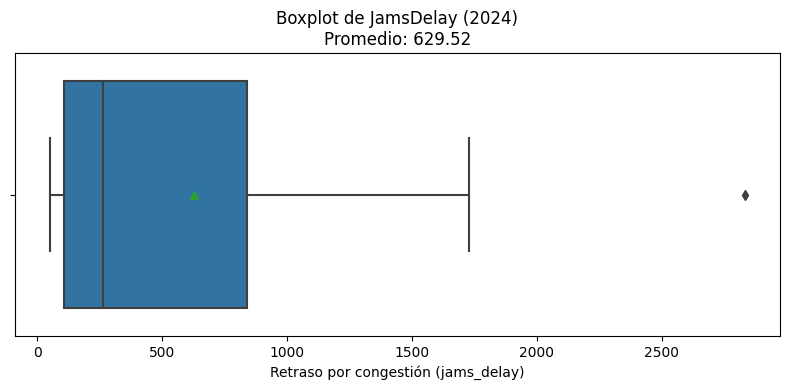

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
import seaborn as sns
sns.boxplot(data=merged, x="jams_delay", showmeans=True)
# crea tu gráfico

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.xlabel("Retraso por congestión (jams_delay)")
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.tight_layout()
plt.show()


In [ ]:
merged["jams_delay"].agg(["count", "mean", "median", "min", "max"])

count       15.000000
mean       629.517204
median     263.047879
min         50.201092
max       2833.057892
Name: jams_delay, dtype: float64

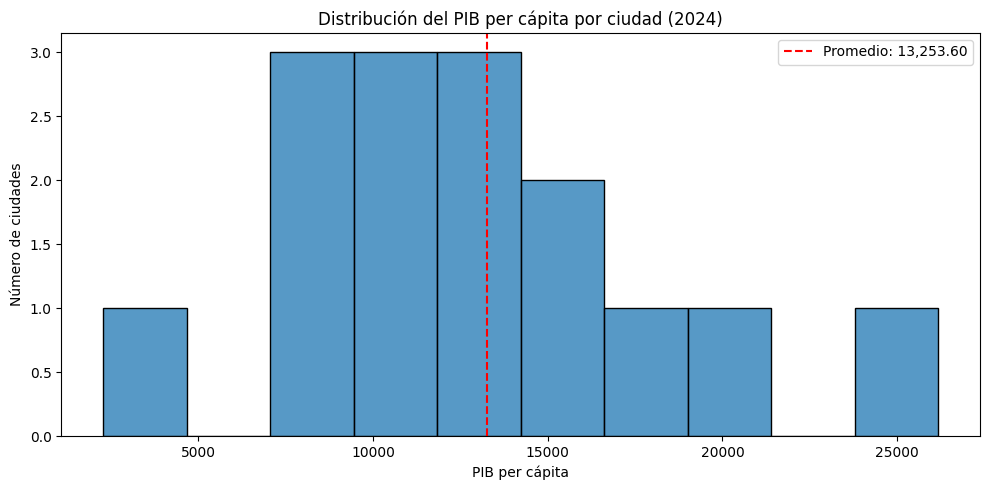

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
mean_gdp = merged["city_gdp_capita"].mean()

plt.figure(figsize=(10, 5))
sns.histplot(data=merged, x="city_gdp_capita", bins=10)

plt.axvline(
    mean_gdp,
    color="red",
    linestyle="--",
    label=f"Promedio: {mean_gdp:,.2f}"
)

plt.title("Distribución del PIB per cápita por ciudad (2024)")
plt.xlabel("PIB per cápita")
plt.ylabel("Número de ciudades")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
merged["city_gdp_capita"].agg(["count", "mean", "median", "min", "max"])

count        15.0
mean      13253.6
median    12381.0
min        2277.0
max       26176.0
Name: city_gdp_capita, dtype: float64

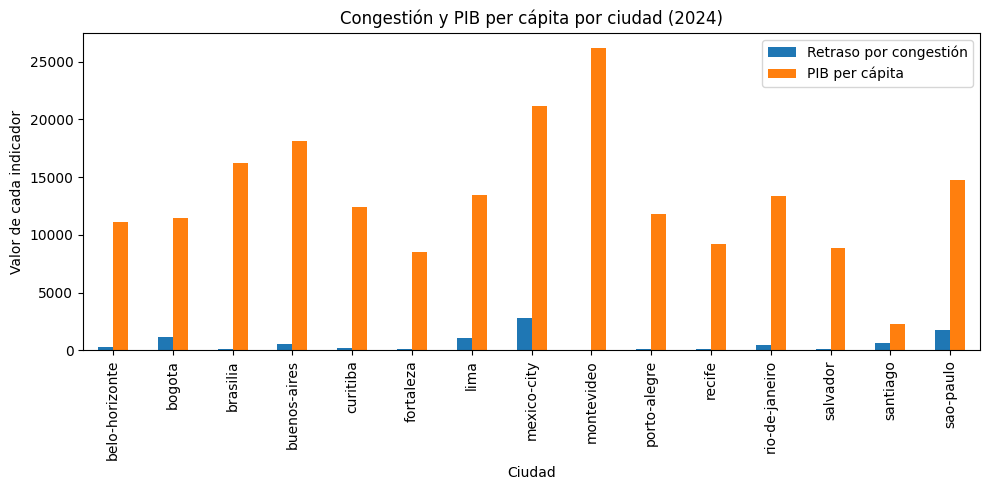

In [ ]:


# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.plot(kind="bar",
            x="city",
            y=["jams_delay", "city_gdp_capita"],
           figsize=(10,5)
           )

plt.title("Congestión y PIB per cápita por ciudad (2024)")
plt.xlabel("Ciudad")
plt.ylabel("Valor de cada indicador")
plt.legend(["Retraso por congestión", "PIB per cápita"])
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()




In [ ]:
merged[["city","jams_delay","city_gdp_capita"]].sort_values("city_gdp_capita", ascending=False).style.format({
    "jams_delay": "{:,.2f}",
    "city_gdp_capita": "{:,.0f}"
})

,city,jams_delay,city_gdp_capita
8,montevideo,50.20,"26,176"
7,mexico-city,"2,833.06","21,111"
3,buenos-aires,571.09,"18,117"
2,brasilia,101.58,"16,251"
14,sao-paulo,"1,729.19","14,703"
6,lima,"1,052.29","13,472"
11,rio-de-janeiro,466.06,"13,349"
4,curitiba,183.47,"12,381"
9,porto-alegre,139.38,"11,801"
1,bogota,"1,141.55","11,442"


**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?


En las 15 ciudades analizadas durante 2024, los graficos no muestran una relación clara y uniforme entre el PIB per cápita y el retraso por congestión. Por ejemplo, Montevideo presenta el mayor PIB per cápita (26,176) y una congestión relativamente baja (50.20), mientras que Ciudad de México registra el mayor retraso por congestión(2833.06) y un PIB per cápita también elevado(21,111).

Esta comparación muestra que un mayor PIB per cápita no siempre va acompañado de mayor congestión. En las ciudades analizadas, los gráficos presentan situaciones distintas y no permiten establecer una relación directa entre ambos indicadores.


<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Excelente conclusión analítica argumentando la falta de relación directa entre PIB per cápita y congestión.
</div>


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:

# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)



---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).


---

# 🧾 Resumen ejecutivo

**Contexto & objetivo:**  
- El análisis explora la relación entre la movilidad urbana y el desempeño económico de las ciudades durante 2024.
- Se examinan el retraso por congestión (jams_delay), el índice de tráfico (traffic_index_live) y los tiempos de viaje por cada 10 kilómetros, junto con el PIB per cápita (city_gdp_capita) como indicador económico de referencia.
- El objetivo es identificar patrones que orienten la evaluación de necesidades de transporte, considerando que el PIB per cápita no mide directamente la productividad laboral.

**Cobertura de datos:**  
- El dataset final incluye 15 ciudades de siete países: Argentina, Brasil, Chile, Colombia, México, Perú y Uruguay, con 14 columnas y una observación por ciudad para 2024.
- La cobertura corresponde a las ciudades con información coincidente en las fuentes de tráfico y economía. Por ello, los resultados describen diferencias entre ciudades durante ese año, no cambios a lo largo del tiempo.

**Metodología (alto nivel):**  
- Se estandarizaron los nombres de las columnas y los formatos necesarios para integrar las fuentes.
- La población se convirtió de millones a habitantes, se redondeó y se almacenó como entero.
- Los datos de tráfico se agregaron por ciudad–año y se combinaron con los indicadores económicos mediante una unión INNER, conservando los registros coincidentes.
- Los gráficos de barras, el histograma del PIB per cápita y el diagrama de caja del retraso permitieron revisar distribuciones, contrastes y valores atípicos.
- El dataset final se exportó como ladb_mobility_economy_2024_clean.csv, sin índice.

**Hallazgos iniciales:**  
- Ciudad de México presenta el mayor retraso por congestión (2,833.06), identificado como valor atípico, seguida de São Paulo (1,729.19) y Bogotá (1,141.55).
- Bogotá registra el mayor índice de tráfico (37.61), mientras que Lima presenta el mayor tiempo de viaje por cada 10 kilómetros (25.67 minutos).
- Montevideo combina el mayor PIB per cápita (26,176) con el menor retraso (50.20), lo que evidencia que los indicadores no siguen un patrón uniforme.
- El PIB per cápita de Santiago (2,277) destaca por su distancia respecto al resto y requiere validación en la fuente.

**Recomendaciones**  
- Se propone Bogotá como candidata para una evaluación prioritaria de transporte: dentro de las 15 ciudades, combina el mayor índice de tráfico, un retraso superior al promedio (1,141.55 frente a 629.52) y un PIB per cápita inferior al promedio (11,442 frente a 13,253.60).
- Lima merece atención por sus mayores tiempos de viaje, y Ciudad de México y São Paulo por sus elevados retrasos.
- Se recomienda evaluar corredores críticos y alternativas de transporte público, estimando costos y beneficios antes de asignar inversiones, y validar el dato económico de Santiago.
- Esta priorización se basa en la comparación de los indicadores disponibles (retraso por congestión, índice de tráfico, tiempos de viaje y PIB per cápita). El análisis es descriptivo y no permite afirmar que exista una relación estadísticamente significativa entre congestión y PIB per cápita, ni que una variable cause cambios en la otra.
